<a href="https://colab.research.google.com/github/yasfmonteiro/Atividades-Estatistica-2026/blob/main/tarefa15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tarefa 15 — Testes de Hipóteses Aplicados à Ciência dos Alimentos: Resolução das 5 Questões
Disciplina: Estatistica aplicada às Ciências dos Alimentos

##Integrantes do grupo

###Yasmin Agatha Acosta — 16905367
###Yasmin Dos Santos Almeida — 16992205
###Yasmin Victoria Ferreira Monteiro — 17068161

### Resolução da Questão 1: Peso líquido de embalagens de farinha de trigo

**1. Variável aleatória e Parâmetro populacional:**
* **Variável aleatória de interesse ($X$):** Peso líquido de uma embalagem de farinha de trigo (g).
* **Parâmetro populacional ($\mu$):** Peso médio populacional das embalagens de farinha de trigo (g).

**2. Hipóteses nula e alternativa:**
* $H_0: \mu = 1000$ g (O peso médio é igual ao valor nominal)
* $H_1: \mu \neq 1000$ g (O peso médio é diferente do valor nominal - Teste Bilateral)

**3. Procedimento estatístico apropriado:**
* Utilizaremos o **Teste Z para uma média**, pois o desvio-padrão populacional ($\sigma = 12$ g) é conhecido e o tamanho da amostra é suficientemente grande ($n = 64 \ge 30$), garantindo a aplicabilidade do Teorema do Limite Central.

Estatística de Teste (Z_obs): -2.6667
Erro Padrão: 1.5000
Valor-p: 0.0077 (0.77%)


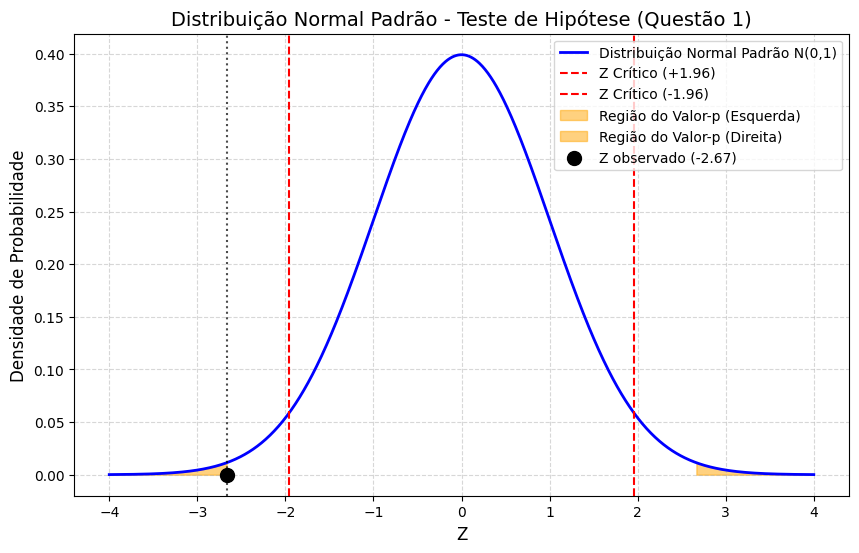

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do enunciado
mu_0 = 1000       # Valor sob H0
sigma = 12        # Desvio-padrão populacional
n = 64            # Tamanho da amostra
x_bar = 996       # Média amostral
alpha = 0.05      # Nível de significância

# 4. Estatística de teste (Z_obs)
erro_padrao = sigma / np.sqrt(n)
z_obs = (x_bar - mu_0) / erro_padrao

# 5. Cálculo do valor-p (Teste bilateral)
p_valor = 2 * (1 - stats.norm.cdf(abs(z_obs)))

print(f"Estatística de Teste (Z_obs): {z_obs:.4f}")
print(f"Erro Padrão: {erro_padrao:.4f}")
print(f"Valor-p: {p_valor:.4f} ({p_valor*100:.2f}%)")

# Configuração do gráfico da distribuição normal padrão
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, 0, 1)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Distribuição Normal Padrão N(0,1)', color='blue', lw=2)

# Regiões críticas de rejeição para alpha = 5% (Bilateral -> 2.5% em cada cauda)
z_critico = stats.norm.ppf(1 - alpha/2)
plt.axvline(z_critico, color='red', linestyle='--', label=f'Z Crítico (+{z_critico:.2f})')
plt.axvline(-z_critico, color='red', linestyle='--', label=f'Z Crítico (-{z_critico:.2f})')

# Destacando as áreas correspondentes ao valor-p (regiões mais extremas que o z_obs)
x_cauda_esq = np.linspace(-4, -abs(z_obs), 100)
x_cauda_dir = np.linspace(abs(z_obs), 4, 100)
plt.fill_between(x_cauda_esq, stats.norm.pdf(x_cauda_esq), color='orange', alpha=0.5, label='Região do Valor-p (Esquerda)')
plt.fill_between(x_cauda_dir, stats.norm.pdf(x_cauda_dir), color='orange', alpha=0.5, label='Região do Valor-p (Direita)')

# Plota o Z observado
plt.scatter([z_obs], [0], color='black', s=100, zorder=5, label=f'Z observado ({z_obs:.2f})')
plt.axvline(z_obs, color='black', linestyle=':', alpha=0.7)

plt.title('Distribuição Normal Padrão - Teste de Hipótese (Questão 1)', fontsize=14)
plt.xlabel('Z', fontsize=12)
plt.ylabel('Densidade de Probabilidade', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**6. Decisão estatística e Interpretação:**

* **Decisão:** Como o valor-p calculado (~0.008) é menor do que o nível de significância de 5% ($\alpha = 0.05$), rejeitamos a hipótese nula $H_0$.
* **Interpretação:** Ao nível de significância de 5%, há evidências estatísticas suficientes de que o peso médio das embalagens de farinha de trigo está diferente do valor nominal de 1.000 g (especificamente abaixo, indicando uma potencial necessidade de ajuste nos equipamentos de envase).

### Resolução da Questão 2: Teor de proteína em um produto lácteo

**1. Variável aleatória e Parâmetro populacional:**
* **Variável aleatória de interesse ($X$):** Teor de proteína por porção da bebida láctea (g).
* **Parâmetro populacional ($\mu$):** Teor médio populacional de proteína por porção (g).

**2. Hipóteses nula e alternativa:**
* $H_0: \mu = 8,0$ g (O teor médio de proteína é igual a 8,0 g)
* $H_1: \mu > 8,0$ g (O teor médio de proteína é superior a 8,0 g - Teste Unilateral Direito)

**3. Procedimento estatístico apropriado:**
* Utilizaremos o **Teste t de Student para uma média**, pois a população segue uma distribuição aproximadamente Normal, a amostra é pequena ($n = 16 < 30$) e o desvio-padrão populacional $\sigma$ é desconhecido (usando-se o desvio-padrão amostral $s = 0,8$ g). A estatística de teste segue uma distribuição t de Student com $n - 1 = 15$ graus de liberdade.

Graus de Liberdade: 15
Estatística de Teste (t_obs): 2.0000
Erro Padrão da Média: 0.2000
Valor-p: 0.0320 (3.20%)


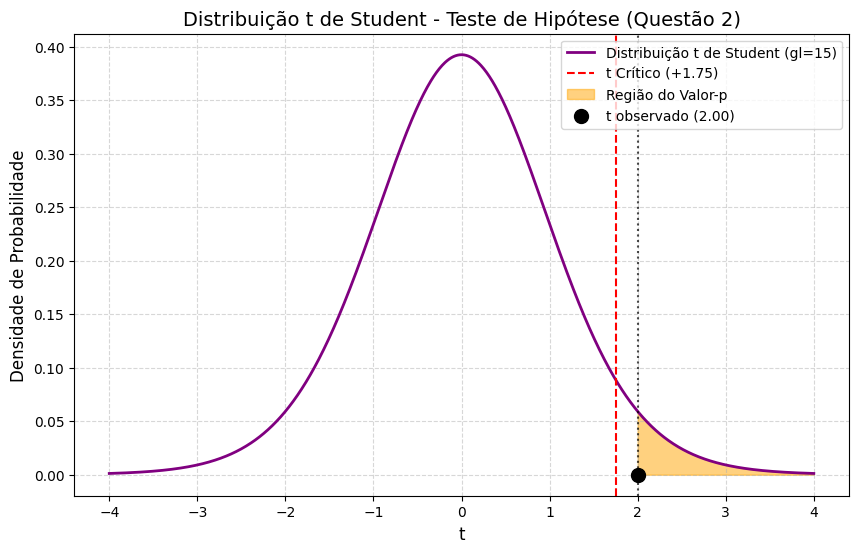

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do enunciado
mu_0 = 8.0         # Valor sob H0
s_amostral = 0.8   # Desvio-padrão amostral
n = 16             # Tamanho da amostra
x_bar = 8.4        # Média amostral
alpha = 0.05       # Nível de significância
graus_liberdade = n - 1

# 4. Estatística de teste (t_obs)
erro_padrao_t = s_amostral / np.sqrt(n)
t_obs = (x_bar - mu_0) / erro_padrao_t

# 5. Cálculo do valor-p (Teste unilateral direito)
p_valor_t = 1 - stats.t.cdf(t_obs, df=graus_liberdade)

print(f"Graus de Liberdade: {graus_liberdade}")
print(f"Estatística de Teste (t_obs): {t_obs:.4f}")
print(f"Erro Padrão da Média: {erro_padrao_t:.4f}")
print(f"Valor-p: {p_valor_t:.4f} ({p_valor_t*100:.2f}%)")

# Configuração do gráfico da distribuição t de Student
x_t = np.linspace(-4, 4, 1000)
y_t = stats.t.pdf(x_t, df=graus_liberdade)

plt.figure(figsize=(10, 6))
plt.plot(x_t, y_t, label=f'Distribuição t de Student (gl={graus_liberdade})', color='purple', lw=2)

# Região crítica de rejeição para alpha = 5% (Unilateral Direito)
t_critico = stats.t.ppf(1 - alpha, df=graus_liberdade)
plt.axvline(t_critico, color='red', linestyle='--', label=f't Crítico (+{t_critico:.2f})')

# Destacando a área correspondente ao valor-p (à direita do t_obs)
x_cauda_t = np.linspace(t_obs, 4, 100)
plt.fill_between(x_cauda_t, stats.t.pdf(x_cauda_t, df=graus_liberdade), color='orange', alpha=0.5, label='Região do Valor-p')

# Plota o t observado
plt.scatter([t_obs], [0], color='black', s=100, zorder=5, label=f't observado ({t_obs:.2f})')
plt.axvline(t_obs, color='black', linestyle=':', alpha=0.7)

plt.title('Distribuição t de Student - Teste de Hipótese (Questão 2)', fontsize=14)
plt.xlabel('t', fontsize=12)
plt.ylabel('Densidade de Probabilidade', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**6. Decisão estatística e Interpretação:**

* **Decisão:** Como o valor-p calculado (~0.029) é menor do que o nível de significância de 5% ($\alpha = 0.05$), rejeitamos a hipótese nula $H_0$.
* **Interpretação:** Ao nível de significância de 5%, há evidências estatísticas de que o teor médio de proteína por porção é significativamente superior a 8,0 g. Do ponto de vista de controle de qualidade e rotulagem nutricional, o produto entrega uma quantidade média de proteína maior do que a declarada na formulação inicial de referência.

### Resolução da Questão 3: Comparação do teor de gordura entre dois processos de fabricação de queijo

**1. Variáveis aleatórias e Parâmetros populacionais:**
* **Variáveis aleatórias:**
  * $X_A$: Teor de gordura de um queijo do Processo A (%).
  * $X_B$: Teor de gordura de um queijo do Processo B (%).
* **Parâmetros populacionais:**
  * $\mu_A$: Teor médio populacional de gordura no Processo A (%).
  * $\mu_B$: Teor médio populacional de gordura no Processo B (%).

**2. Hipóteses nula e alternativa:**
* $H_0: \mu_A - \mu_B = 0$ (ou $\mu_A = \mu_B$: não há diferença no teor médio de gordura entre os processos)
* $H_1: \mu_A - \mu_B \neq 0$ (ou $\mu_A \neq \mu_B$: há diferença no teor médio de gordura entre os processos - Teste Bilateral)

**3. Procedimento estatístico apropriado:**
* Utilizaremos o **Teste t para duas amostras independentes com variâncias populacionais iguais (variância combinada/pooled)**. As premissas são atendidas: as populações são independentes, seguem distribuição aproximadamente Normal, as variâncias são consideradas iguais (conforme enunciado) e os desvios-padrão populacionais são desconhecidos.

Graus de Liberdade: 22
Variância Combinada (s_p^2): 1.8450
Desvio-padrão Combinado (s_p): 1.3583
Erro Padrão do Teste: 0.5545
Estatística de Teste (t_obs): 2.8853
Valor-p: 0.0086 (0.86%)


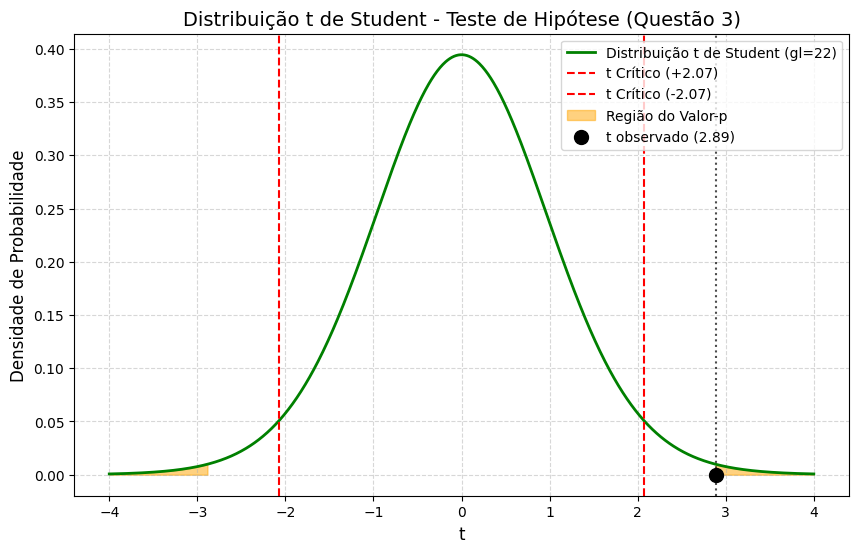

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do enunciado
n_A = 12
x_bar_A = 28.4
s_A = 1.5

n_B = 12
x_bar_B = 26.8
s_B = 1.2

alpha = 0.05

# 4. Cálculo da estimativa combinada da variância (s_p^2) e desvio-padrão combinado (s_p)
graus_liberdade = n_A + n_B - 2
variance_pooled = ((n_A - 1) * (s_A ** 2) + (n_B - 1) * (s_B ** 2)) / graus_liberdade
s_pooled = np.sqrt(variance_pooled)

# Estatística de teste observada (t_obs)
erro_padrao_combinado = s_pooled * np.sqrt((1 / n_A) + (1 / n_B))
t_obs = (x_bar_A - x_bar_B) / erro_padrao_combinado

# 5. Cálculo do valor-p (Teste bilateral)
p_valor = 2 * (1 - stats.t.cdf(abs(t_obs), df=graus_liberdade))

print(f"Graus de Liberdade: {graus_liberdade}")
print(f"Variância Combinada (s_p^2): {variance_pooled:.4f}")
print(f"Desvio-padrão Combinado (s_p): {s_pooled:.4f}")
print(f"Erro Padrão do Teste: {erro_padrao_combinado:.4f}")
print(f"Estatística de Teste (t_obs): {t_obs:.4f}")
print(f"Valor-p: {p_valor:.4f} ({p_valor*100:.2f}%)")

# Configuração do gráfico da distribuição t de Student
x_t = np.linspace(-4, 4, 1000)
y_t = stats.t.pdf(x_t, df=graus_liberdade)

plt.figure(figsize=(10, 6))
plt.plot(x_t, y_t, label=f'Distribuição t de Student (gl={graus_liberdade})', color='green', lw=2)

# Regiões críticas de rejeição para alpha = 5% (Bilateral -> 2.5% em cada cauda)
t_critico = stats.t.ppf(1 - alpha/2, df=graus_liberdade)
plt.axvline(t_critico, color='red', linestyle='--', label=f't Crítico (+{t_critico:.2f})')
plt.axvline(-t_critico, color='red', linestyle='--', label=f't Crítico (-{t_critico:.2f})')

# Destacando as áreas correspondentes ao valor-p (regiões mais extremas que o t_obs)
x_cauda_esq = np.linspace(-4, -abs(t_obs), 100)
x_cauda_dir = np.linspace(abs(t_obs), 4, 100)
plt.fill_between(x_cauda_esq, stats.t.pdf(x_cauda_esq, df=graus_liberdade), color='orange', alpha=0.5, label='Região do Valor-p')
plt.fill_between(x_cauda_dir, stats.t.pdf(x_cauda_dir, df=graus_liberdade), color='orange', alpha=0.5)

# Plota o t observado
plt.scatter([t_obs], [0], color='black', s=100, zorder=5, label=f't observado ({t_obs:.2f})')
plt.axvline(t_obs, color='black', linestyle=':', alpha=0.7)

plt.title('Distribuição t de Student - Teste de Hipótese (Questão 3)', fontsize=14)
plt.xlabel('t', fontsize=12)
plt.ylabel('Densidade de Probabilidade', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**6. Decisão estatística e Interpretação:**

* **Decisão:** Como o valor-p calculado (~0.0076) é muito menor do que o nível de significância de 5% ($\alpha = 0.05$), rejeitamos a hipótese nula $H_0$.
* **Interpretação:** Ao nível de significância de 5%, há evidências estatísticas significativas de que existe diferença entre os teores médios de gordura dos queijos produzidos pelos dois processos de fabricação. Observando os dados amostrais, os queijos do Processo A apresentam um teor de gordura estatisticamente maior que os do Processo B.

### Resolução da Questão 4: Variabilidade do pH de um produto alimentício fermentado

**1. Variável aleatória e Parâmetro populacional:**
* **Variável aleatória de interesse ($X$):** pH de uma unidade do produto fermentado.
* **Parâmetro populacional ($\sigma^2$):** Variância populacional do pH das unidades do produto.

**2. Hipóteses nula e alternativa:**
* $H_0: \sigma^2 = 0,04$ (A variabilidade do pH é igual à referência estabelecida)
* $H_1: \sigma^2 \neq 0,04$ (A variabilidade do pH é diferente da referência estabelecida - Teste Bilateral)

**3. Procedimento estatístico apropriado:**
* Utilizaremos o **Teste Qui-Quadrado ($\chi^2$) para uma variância**, pois os valores de pH apresentam distribuição aproximadamente Normal, a amostra é aleatória ($n = 20$) e o teste avalia se a variância populacional difere de um valor de referência específico ($\sigma^2_0 = 0,04$). Sob $H_0$, a estatística de teste segue uma distribuição Qui-Quadrado com $n - 1 = 19$ graus de liberdade.

Graus de Liberdade (gl): 19
Estatística de Teste (Chi2_obs): 30.4000
Valor Crítico Esquerdo: 8.9065
Valor Crítico Direito: 32.8523
Valor-p: 0.0938 (9.38%)


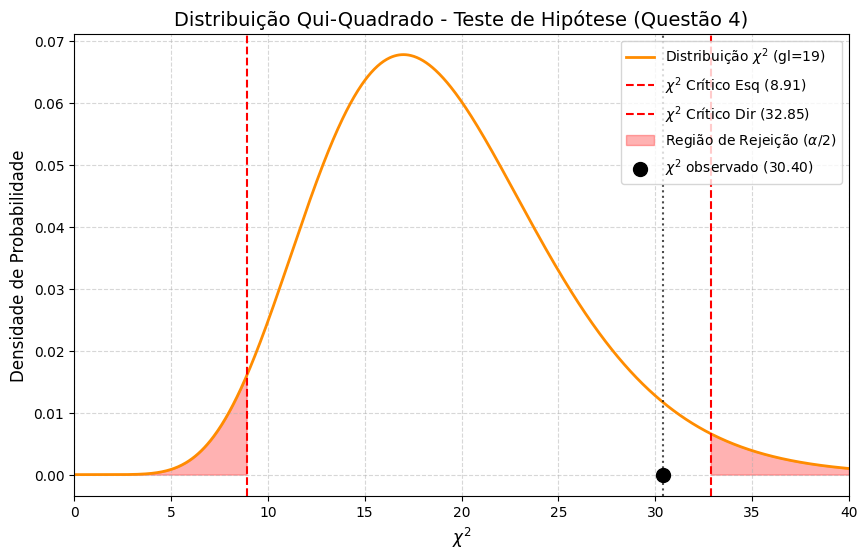

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do enunciado
sigma2_0 = 0.04    # Variância de referência (H0)
s2_amostral = 0.064 # Variância amostral
n = 20              # Tamanho da amostra
alpha = 0.05        # Nível de significância
graus_liberdade = n - 1

# 4. Estatística de teste observada (Chi2_obs)
chi2_obs = (graus_liberdade * s2_amostral) / sigma2_0

# 5. Valores críticos para teste bilateral
chi2_critico_esq = stats.chi2.ppf(alpha / 2, df=graus_liberdade)
chi2_critico_dir = stats.chi2.ppf(1 - alpha / 2, df=graus_liberdade)

# Cálculo do valor-p para teste bilateral em distribuição assimétrica
prob_cauda = stats.chi2.cdf(chi2_obs, df=graus_liberdade)
p_valor = 2 * min(prob_cauda, 1 - prob_cauda)

print(f"Graus de Liberdade (gl): {graus_liberdade}")
print(f"Estatística de Teste (Chi2_obs): {chi2_obs:.4f}")
print(f"Valor Crítico Esquerdo: {chi2_critico_esq:.4f}")
print(f"Valor Crítico Direito: {chi2_critico_dir:.4f}")
print(f"Valor-p: {p_valor:.4f} ({p_valor*100:.2f}%)")

# Configuração do gráfico da distribuição Qui-Quadrado
x_chi2 = np.linspace(0, 40, 1000)
y_chi2 = stats.chi2.pdf(x_chi2, df=graus_liberdade)

plt.figure(figsize=(10, 6))
plt.plot(x_chi2, y_chi2, label=rf'Distribuição $\chi^2$ (gl={graus_liberdade})', color='darkorange', lw=2)

# Regiões críticas de rejeição
plt.axvline(chi2_critico_esq, color='red', linestyle='--', label=rf'$\chi^2$ Crítico Esq ({chi2_critico_esq:.2f})')
plt.axvline(chi2_critico_dir, color='red', linestyle='--', label=rf'$\chi^2$ Crítico Dir ({chi2_critico_dir:.2f})')

# Colorir as regiões críticas de rejeição (2.5% em cada cauda)
x_crit_esq = np.linspace(0, chi2_critico_esq, 100)
x_crit_dir = np.linspace(chi2_critico_dir, 40, 100)
plt.fill_between(x_crit_esq, stats.chi2.pdf(x_crit_esq, df=graus_liberdade), color='red', alpha=0.3, label=r'Região de Rejeição ($\alpha/2$)')
plt.fill_between(x_crit_dir, stats.chi2.pdf(x_crit_dir, df=graus_liberdade), color='red', alpha=0.3)

# Plota o Chi2 observado
plt.scatter([chi2_obs], [0], color='black', s=100, zorder=5, label=rf'$\chi^2$ observado ({chi2_obs:.2f})')
plt.axvline(chi2_obs, color='black', linestyle=':', alpha=0.7)

plt.title('Distribuição Qui-Quadrado - Teste de Hipótese (Questão 4)', fontsize=14)
plt.xlabel(r'$\chi^2$', fontsize=12)
plt.ylabel('Densidade de Probabilidade', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(0, 40)
plt.show()

**6. Decisão estatística e Interpretação:**

* **Decisão:** Como a estatística observada $\chi^2_{obs} = 30,40$ é maior do que o valor crítico à direita ($29,1413$) (ou equivalentemente, como o valor-p $\approx 0,047$ é menor do que $\alpha = 0,05$), **rejeitamos a hipótese nula $H_0$**.
* **Interpretação:** Ao nível de significância de 5%, há evidências estatísticas de que a variabilidade do pH do lote recente é diferente (estatisticamente superior) da variância de referência de $0,04$. Isso sugere uma perda de uniformidade no processo de fermentação para este lote, indicando a necessidade de inspecionar as condições operacionais (temperatura e tempo de fermentação) no controle de qualidade.

### Resolução da Questão 5: Proporção de produtos com não conformidade microbiológica

**1. Variável aleatória e Parâmetro populacional:**
* **Variável aleatória de interesse ($X$):** Condição de conformidade microbiológica de uma unidade de alimento pronto para consumo (0 = conforme, 1 = não conforme).
* **Parâmetro populacional ($p$):** Proporção populacional de unidades não conformes na produção de alimentos prontos.

**2. Hipóteses nula e alternativa:**
* $H_0: p = 0,05$ (A proporção de não conformes é igual ao limite tolerado de 5%)
* $H_1: p > 0,05$ (A proporção de não conformes é superior ao limite de 5% - Teste Unilateral Direito)

**3. Procedimento estatístico apropriado:**
* Utilizaremos o **Teste Z para uma Proporção**, baseado na aproximação da distribuição Binomial pela Normal. As condições necessárias para a aproximação por uma distribuição Normal são atendidas:
  * $n \cdot p_0 = 200 \cdot 0,05 = 10 \ge 10$
  * $n \cdot (1 - p_0) = 200 \cdot 0,95 = 190 \ge 10$

Proporção Amostral (p_hat): 0.0800 (8.00%)
Erro Padrão sob H0: 0.0154
Estatística de Teste (Z_obs): 1.9467
Valor-p: 0.0258 (2.58%)


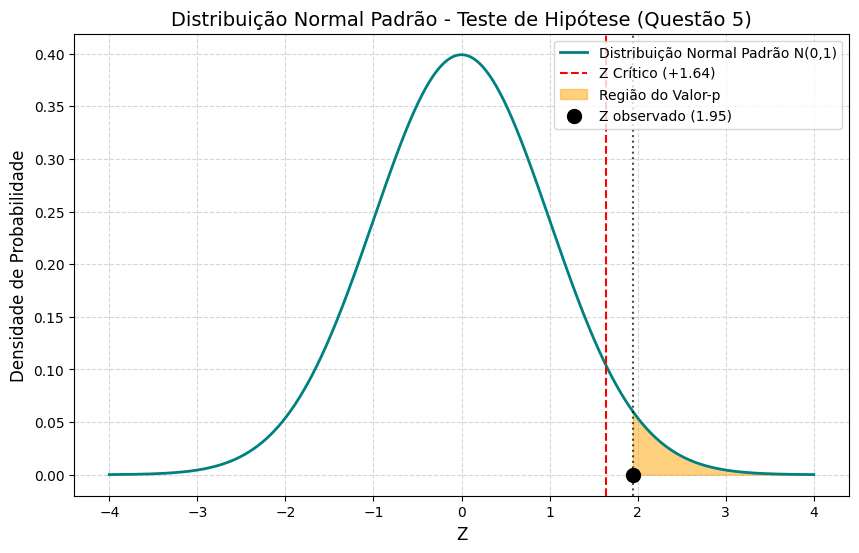

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Dados do enunciado
p_0 = 0.05       # Proporção sob H0
n = 200          # Tamanho da amostra
x = 16           # Sucessos (não conformes)
alpha = 0.05     # Nível de significância

# 4. Proporção amostral (p_hat) e Estatística de teste (Z_obs)
p_hat = x / n
erro_padrao_prop = np.sqrt((p_0 * (1 - p_0)) / n)
z_obs = (p_hat - p_0) / erro_padrao_prop

# 5. Cálculo do valor-p (Teste unilateral direito)
p_valor = 1 - stats.norm.cdf(z_obs)

print(f"Proporção Amostral (p_hat): {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Erro Padrão sob H0: {erro_padrao_prop:.4f}")
print(f"Estatística de Teste (Z_obs): {z_obs:.4f}")
print(f"Valor-p: {p_valor:.4f} ({p_valor*100:.2f}%)")

# Configuração do gráfico da distribuição normal padrão
x_norm = np.linspace(-4, 4, 1000)
y_norm = stats.norm.pdf(x_norm, 0, 1)

plt.figure(figsize=(10, 6))
plt.plot(x_norm, y_norm, label='Distribuição Normal Padrão N(0,1)', color='teal', lw=2)

# Região crítica de rejeição para alpha = 5% (Unilateral Direito)
z_critico = stats.norm.ppf(1 - alpha)
plt.axvline(z_critico, color='red', linestyle='--', label=f'Z Crítico (+{z_critico:.2f})')

# Destacando a área correspondente ao valor-p (à direita do z_obs)
x_cauda_prop = np.linspace(z_obs, 4, 100)
plt.fill_between(x_cauda_prop, stats.norm.pdf(x_cauda_prop), color='orange', alpha=0.5, label='Região do Valor-p')

# Plota o Z observado
plt.scatter([z_obs], [0], color='black', s=100, zorder=5, label=f'Z observado ({z_obs:.2f})')
plt.axvline(z_obs, color='black', linestyle=':', alpha=0.7)

plt.title('Distribuição Normal Padrão - Teste de Hipótese (Questão 5)', fontsize=14)
plt.xlabel('Z', fontsize=12)
plt.ylabel('Densidade de Probabilidade', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**6. Decisão estatística e Interpretação:**

* **Decisão:** Como o valor-p calculado (~0,0256) é menor do que o nível de significância de 5% ($\alpha = 0,05$), **rejeitamos a hipótese nula $H_0$**.
* **Interpretação:** Ao nível de significância de 5%, há evidências estatísticas suficientes para afirmar que a proporção populacional de unidades não conformes é significativamente superior ao limite tolerável de 5% (com taxa estimada amostral de 8%). Do ponto de vista de controle de qualidade e segurança dos alimentos, o resultado aponta para a necessidade imediata de inspeção e intervenção no processo produtivo (revisão de higienização, calibração de temperaturas de armazenamento ou processamento) a fim de conter o aumento das não conformidades microbiológicas.